# Colombo Land Prices: Data Preparation

Implements the preprocessing decisions agreed so far:

1. Target = `Price per Perch` (drop `Mentioned Price(Rs)` to avoid leakage)
2. Fix the 3 "per acre" rows
3. Remove duplicate listings
4. Log-transform the target, then check outliers with IQR on the log scale
5. Split `Land_type` into yes/no columns

Each section ends with a **Your notes** cell. Fill these in yourself, since they become your report.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)

df = pd.read_excel("Land prices of Colombo district-Sri Lanka.xlsx")
print(df.shape)
df.head()

(4494, 35)


,Address_ID,Address,Land_size(Perches),Price_Scale,Land_type,Posted_Date_new,Distance from fort,count_govtschools_A,min_dist_govtschools_a,count_govtschools_B,min_dist_govtschools_b,count_semigovtschools,min_dist_semigovtschools,count_intlschools,min_dist_intlschools,count_uni,min_dist_uni,min_dist_nearest_express,min_dist_nearest_railway,min_dist_nearest_bank,count_banks_within_2km,min_dist_nearest_FinanceCompany,count_FinanceCompanies_within_2km,min_dist_nearest_Govt_Hospital,count_Govt_Hospitals,min_dist_nearest_Pvt_Hospital,count_Pvt_Hospital,min_dist_nearest_Pvt_Med_center,count_Pvt_Med_Centers,min_dist_nearest_Supermarket,count_Supermarkets_within2km,min_dist_nearest_Fuel_station,count_Fuel_Stations_within2km,Mentioned Price(Rs),Price per Perch
0,6,battaramulla,12.00,per perch,"Commercial, Residential",2021-09-21,11.349555,0,3.099786,3,0.190254,0,3.899165,1,1.322046,0,3.232579,6.632046,4.072472,0.046516,15,0.115222,3,2.304565,0,2.966136,0,0.184196,2,0.275528,11,1.185148,2,3800000,3800000.0
1,12,nawala,22.00,per perch,"Commercial, Residential",2021-09-21,9.160830,2,1.530830,12,0.863357,1,0.906167,4,1.598612,1,0.668116,7.480200,0.647482,0.047407,38,0.491287,7,2.580394,0,0.885503,5,2.102498,0,0.229320,17,1.221396,4,6500000,6500000.0
2,16,mount lavinia,23.00,per perch,Residential,2021-09-21,12.887396,0,2.727171,5,0.191582,2,0.581298,0,2.842966,0,2.847591,12.642444,0.528389,0.028454,12,0.323762,5,3.907213,0,4.077519,0,1.188858,2,0.113300,20,1.052876,5,2600000,2600000.0
3,126,divulpitiya,16.05,per perch,"Commercial, Residential",2021-09-21,12.597925,0,2.631805,2,1.238951,2,1.496635,0,2.434278,1,0.986116,9.697738,1.970515,1.328256,20,1.368774,4,2.883591,0,4.266219,0,0.585909,1,0.315818,19,0.523224,3,3700000,3700000.0
4,53,kollupitiya,6.80,per perch,Residential,2021-09-21,4.222136,3,0.838323,8,0.113577,9,0.299523,2,1.342131,2,1.467278,5.676327,0.379337,0.083896,46,0.167803,13,1.459288,3,0.744991,4,1.394043,2,0.234181,17,0.836103,4,85000000,85000000.0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4494 entries, 0 to 4493
Data columns (total 35 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   Address_ID                         4494 non-null   int64         
 1   Address                            4494 non-null   str           
 2   Land_size(Perches)                 4494 non-null   float64       
 3   Price_Scale                        4494 non-null   str           
 4   Land_type                          4494 non-null   str           
 5   Posted_Date_new                    4494 non-null   datetime64[us]
 6   Distance from fort                 4494 non-null   float64       
 7   count_govtschools_A                4494 non-null   int64         
 8   min_dist_govtschools_a             4494 non-null   float64       
 9   count_govtschools_B                4494 non-null   int64         
 10  min_dist_govtschools_b             4494 non-nul

## 1. Target column

`Price per Perch` is the target. `Mentioned Price(Rs)` is either the same number or the target multiplied by
land size, so it must not be used as a feature. `Address_ID` is just a row identifier.

In [3]:
TARGET = "Price per Perch"
df = df.drop(columns=["Address_ID", "Mentioned Price(Rs)"])

## 2. Price scale

Check how `Price per Perch` relates to the advertised price for each `Price_Scale`.
(Run this check **before** dropping `Mentioned Price(Rs)` if you want to reproduce it. The cell below
re-reads the raw file for that reason.)

In [4]:
raw = pd.read_excel("Land prices of Colombo district-Sri Lanka.xlsx")
per_unit = raw["Mentioned Price(Rs)"] / raw["Land_size(Perches)"]

check = raw.assign(
    equals_mentioned=np.isclose(raw[TARGET], raw["Mentioned Price(Rs)"]),
    equals_mentioned_div_size=np.isclose(raw[TARGET], per_unit),
)
check.groupby("Price_Scale")[["equals_mentioned", "equals_mentioned_div_size"]].mean().round(3)

,equals_mentioned,equals_mentioned_div_size
Price_Scale,,
per acre,1.000,0.000
per perch,1.000,0.001
total price,0.001,1.000


In [5]:
# "per acre" rows still hold a per-acre price. 1 acre = 160 perches.
PERCHES_PER_ACRE = 160
acre = df["Price_Scale"] == "per acre"
display(df.loc[acre, ["Address", "Land_size(Perches)", TARGET]])

df.loc[acre, TARGET] = df.loc[acre, TARGET] / PERCHES_PER_ACRE
display(df.loc[acre, ["Address", "Land_size(Perches)", TARGET]])

# Once corrected, Price_Scale only describes how the ad was written, not the land
df = df.drop(columns=["Price_Scale"])

,Address,Land_size(Perches),Price per Perch
672,makandana,6.80,885000.0
2587,puwakpitiya,35.00,2500000.0
2633,piliyandala,6.05,900000.0


,Address,Land_size(Perches),Price per Perch
672,makandana,6.80,5531.25
2587,puwakpitiya,35.00,15625.00
2633,piliyandala,6.05,5625.00


## 3. Duplicates

Removed **before** any train/test split, so the same listing can't appear in both.

In [6]:
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"removed {before - len(df)} duplicate rows -> {len(df)} remain")

removed 198 duplicate rows -> 4296 remain


## 4. Target distribution and outliers

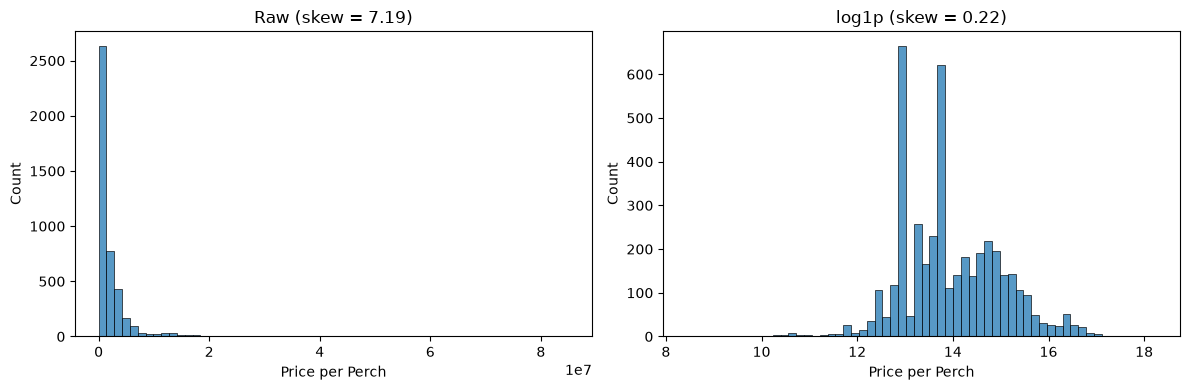

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df[TARGET], bins=60, ax=ax[0]).set_title(f"Raw (skew = {df[TARGET].skew():.2f})")
log_target = np.log1p(df[TARGET])
sns.histplot(log_target, bins=60, ax=ax[1]).set_title(f"log1p (skew = {log_target.skew():.2f})")
plt.tight_layout()

In [8]:
def iqr_mask(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

print("IQR on raw target flags:", iqr_mask(df[TARGET]).sum())
print("IQR on log target flags:", iqr_mask(log_target).sum())

flagged = df[iqr_mask(log_target)].sort_values(TARGET)
flagged[["Address", "Land_size(Perches)", "Land_type", "Distance from fort", TARGET]]

IQR on raw target flags: 297
IQR on log target flags: 21


,Address,Land_size(Perches),Land_type,Distance from fort,Price per Perch
3031,werahera,50.00,Commercial,15.494982,4.600000e+03
645,makandana,6.80,Residential,22.387910,5.531250e+03
2502,piliyandala,6.05,Residential,18.853887,5.625000e+03
2467,puwakpitiya,35.00,"Agricultural, Commercial, Residential, Other",40.834218,1.562500e+04
3140,meegoda,9.70,"Commercial, Residential, Other",26.725765,2.680412e+04
4191,ranala,12.50,"Residential, Other",23.324733,3.000000e+04
2550,piliyandala,70.00,Residential,18.853887,3.142857e+04
2447,kesbewa,70.00,Agricultural,21.209004,3.150000e+04
3260,athurugiriya,7.00,"Commercial, Residential, Other",19.593169,3.500000e+04
3301,meegoda,7.00,"Residential, Other",26.725765,3.571429e+04


In [9]:
# Look at the flagged rows above and decide: typos, or genuine prices?
# Set this to False if you decide to keep them.
DROP_LOG_OUTLIERS = True

if DROP_LOG_OUTLIERS:
    df = df[~iqr_mask(np.log1p(df[TARGET]))].reset_index(drop=True)
df["log_price_per_perch"] = np.log1p(df[TARGET])
print(df.shape)

(4275, 33)


## 5. Land type

A plot can be several types at once, so split the combined label into one yes/no column per type.

In [10]:
land_types = df["Land_type"].str.get_dummies(sep=", ").add_prefix("is_")
df = pd.concat([df.drop(columns=["Land_type"]), land_types], axis=1)
land_types.sum().sort_values(ascending=False)

is_Residential     4135
is_Commercial      1836
is_Other            885
is_Agricultural     152
dtype: int64

## 6. Exploratory analysis of the cleaned data

Two questions before modelling:
1. **How much does price depend on the area?** Median price per perch by area.
2. **Which features move with price, and which move with each other?** Spearman correlations. Spearman is used
   because prices are heavily skewed and the relationships don't have to be straight lines, only consistently
   up or down.

160 areas | listings per area: median 8, min 1, max 317 | areas with fewer than 10 listings: 88


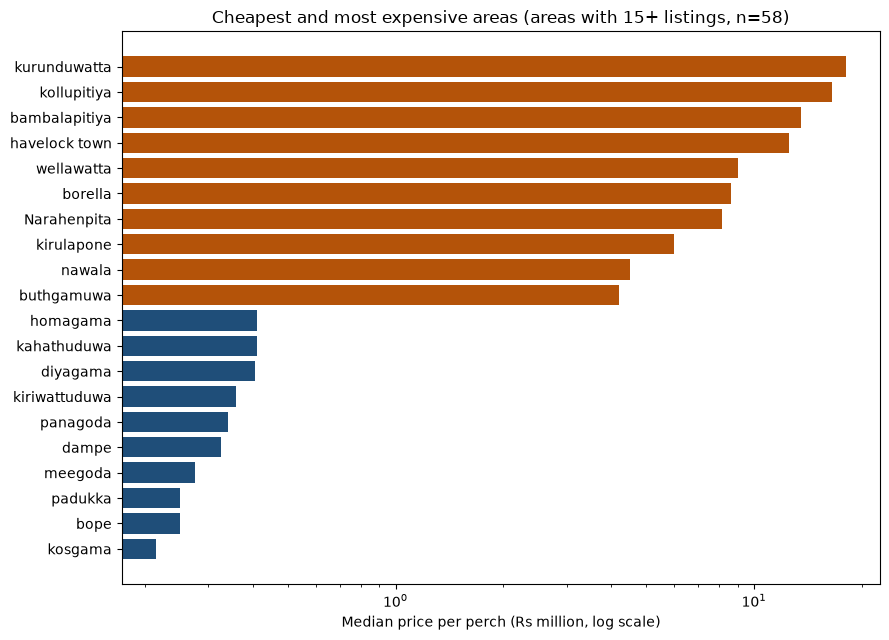

most expensive: kurunduwatta Rs 18,000,000 | cheapest: kosgama Rs 215,000 | ratio 84x


In [11]:
counts = df["Address"].value_counts()
print(f"{df['Address'].nunique()} areas | listings per area: median {counts.median():.0f}, "
      f"min {counts.min()}, max {counts.max()} | areas with fewer than 10 listings: {(counts < 10).sum()}")

by_area = (df[df["Address"].isin(counts[counts >= 15].index)]
           .groupby("Address")[TARGET].median().sort_values())
extremes = pd.concat([by_area.head(10), by_area.tail(10)])

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.barh(extremes.index, extremes.values / 1e6, color=["#1F4E79"] * 10 + ["#B45309"] * 10)
ax.set_xscale("log")
ax.set_xlabel("Median price per perch (Rs million, log scale)")
ax.set_title(f"Cheapest and most expensive areas (areas with 15+ listings, n={len(by_area)})")
plt.tight_layout()
plt.savefig("figures/fig_eda1_price_by_area.png", dpi=110, bbox_inches="tight")
plt.show()
print(f"most expensive: {by_area.index[-1]} Rs {by_area.iloc[-1]:,.0f} | "
      f"cheapest: {by_area.index[0]} Rs {by_area.iloc[0]:,.0f} | ratio {by_area.iloc[-1] / by_area.iloc[0]:.0f}x")

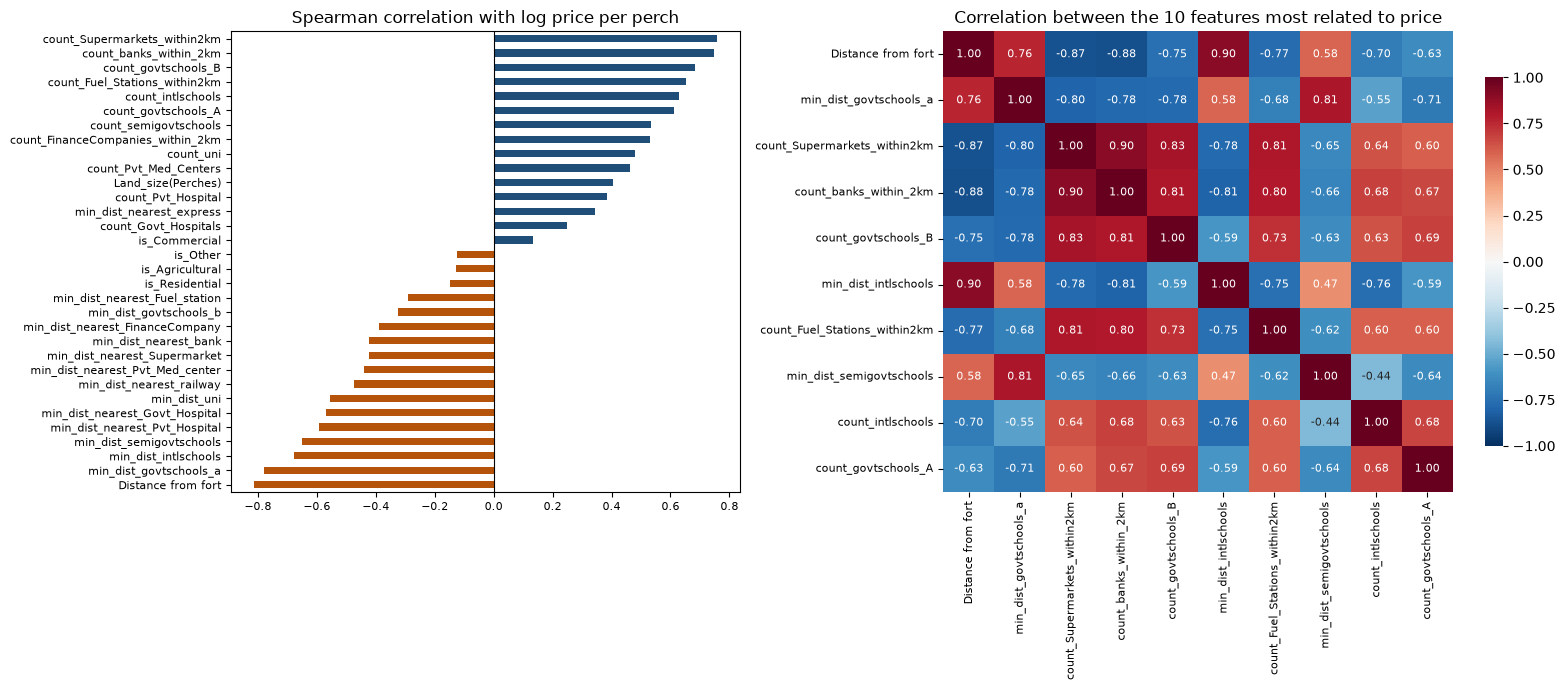

strongest with price:
Distance from fort              -0.813
min_dist_govtschools_a          -0.780
count_Supermarkets_within2km     0.758
count_banks_within_2km           0.748
count_govtschools_B              0.683
min_dist_intlschools            -0.679
count_Fuel_Stations_within2km    0.653
min_dist_semigovtschools        -0.649
count_intlschools                0.628
count_govtschools_A              0.612

pairs among these 10 with |rho| > 0.7: 22 of 45


In [12]:
numeric = [c for c in df.select_dtypes("number").columns if c not in (TARGET, "log_price_per_perch")]
corr_target = df[numeric].corrwith(df["log_price_per_perch"], method="spearman").sort_values()
top = corr_target.abs().sort_values(ascending=False).head(10).index

fig, ax = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1, 1.25]})
corr_target.plot.barh(ax=ax[0], color=["#B45309" if v < 0 else "#1F4E79" for v in corr_target], fontsize=8)
ax[0].axvline(0, color="black", lw=0.8)
ax[0].set_title("Spearman correlation with log price per perch")
sns.heatmap(df[top].corr(method="spearman"), ax=ax[1], cmap="RdBu_r", vmin=-1, vmax=1, annot=True, fmt=".2f",
            annot_kws={"size": 8}, cbar_kws={"shrink": 0.8})
ax[1].set_title("Correlation between the 10 features most related to price")
ax[1].tick_params(labelsize=8)
plt.tight_layout()
plt.savefig("figures/fig_eda2_correlations.png", dpi=110, bbox_inches="tight")
plt.show()

hm = df[top].corr(method="spearman").abs().values
pairs = hm[np.triu_indices_from(hm, k=1)]
print("strongest with price:")
print(corr_target.reindex(top).round(3).to_string())
print(f"\npairs among these 10 with |rho| > 0.7: {(pairs > 0.7).sum()} of {len(pairs)}")

**What the EDA shows**

- **Area dominates price.** Among areas with 15+ listings, the median price per perch ranges from about
  Rs 215,000 (Kosgama) to Rs 18 million (Kurunduwatta), an **84x** difference. The expensive end is central
  Colombo (Colombo 3-7: Kollupitiya, Bambalapitiya, Havelock Town); the cheap end is the outer east and south-east.
- **Many areas are rare.** 88 of the 160 areas have fewer than 10 listings, so the area needs an encoding that
  copes with rare categories (cross-fitted target encoding, or CatBoost), not one-hot encoding.
- **Location features track price strongly.** Distance from Fort has the strongest correlation with log price
  (rho = -0.81), followed by distance to grade-A schools (-0.78) and supermarkets/banks within 2 km (+0.76/+0.75).
- **The location features are highly correlated with each other**: 22 of the 45 pairs among the top 10 have
  |rho| > 0.7. They mostly describe one thing, how central and built-up the area is. This is why Random Forest
  should consider only a subset of features at each split, and why individual importances must be read as a group.
- **Land size correlates positively with price per perch (rho = +0.40)**, which is unexpected and discussed
  in the report (Section 6.1).

## Decided in the next notebooks

- **`Address`:** target-encoded for RF/XGBoost/LightGBM/Ridge; handled natively by CatBoost.
- **`Posted_Date_new`:** dropped (all listings within about 8 weeks).
- **Scaling:** only for the Ridge baseline.
- **Hold-out row:** one listing set aside at the start of `02_modelling.ipynb`.

In [13]:
df.to_csv("land_prices_clean.csv", index=False)
print(df.shape)
df.head()

(4275, 36)


,Address,Land_size(Perches),Posted_Date_new,Distance from fort,count_govtschools_A,min_dist_govtschools_a,count_govtschools_B,min_dist_govtschools_b,count_semigovtschools,min_dist_semigovtschools,count_intlschools,min_dist_intlschools,count_uni,min_dist_uni,min_dist_nearest_express,min_dist_nearest_railway,min_dist_nearest_bank,count_banks_within_2km,min_dist_nearest_FinanceCompany,count_FinanceCompanies_within_2km,min_dist_nearest_Govt_Hospital,count_Govt_Hospitals,min_dist_nearest_Pvt_Hospital,count_Pvt_Hospital,min_dist_nearest_Pvt_Med_center,count_Pvt_Med_Centers,min_dist_nearest_Supermarket,count_Supermarkets_within2km,min_dist_nearest_Fuel_station,count_Fuel_Stations_within2km,Price per Perch,log_price_per_perch,is_Agricultural,is_Commercial,is_Other,is_Residential
0,battaramulla,12.00,2021-09-21,11.349555,0,3.099786,3,0.190254,0,3.899165,1,1.322046,0,3.232579,6.632046,4.072472,0.046516,15,0.115222,3,2.304565,0,2.966136,0,0.184196,2,0.275528,11,1.185148,2,3800000.0,15.150512,0,1,0,1
1,nawala,22.00,2021-09-21,9.160830,2,1.530830,12,0.863357,1,0.906167,4,1.598612,1,0.668116,7.480200,0.647482,0.047407,38,0.491287,7,2.580394,0,0.885503,5,2.102498,0,0.229320,17,1.221396,4,6500000.0,15.687313,0,1,0,1
2,mount lavinia,23.00,2021-09-21,12.887396,0,2.727171,5,0.191582,2,0.581298,0,2.842966,0,2.847591,12.642444,0.528389,0.028454,12,0.323762,5,3.907213,0,4.077519,0,1.188858,2,0.113300,20,1.052876,5,2600000.0,14.771022,0,0,0,1
3,divulpitiya,16.05,2021-09-21,12.597925,0,2.631805,2,1.238951,2,1.496635,0,2.434278,1,0.986116,9.697738,1.970515,1.328256,20,1.368774,4,2.883591,0,4.266219,0,0.585909,1,0.315818,19,0.523224,3,3700000.0,15.123844,0,1,0,1
4,pannipitiya,8.00,2021-09-21,17.259766,1,1.894473,4,0.432120,1,0.505464,0,5.654085,0,3.092684,3.716698,0.089602,0.104367,10,1.576947,2,3.520512,0,1.382255,1,2.364928,0,0.685838,5,0.917733,2,1650000.0,14.316286,0,0,0,1


## Summary

- **Target:** price per perch, so plots of different sizes are comparable. `Mentioned Price(Rs)` removed (leakage).
- **Price scale:** "per perch" and "total price" rows were already converted correctly; the 3 "per acre" rows
  held a per-acre price and were divided by 160.
- **Duplicates:** 198 removed, more than the 177 in the raw file, because some listings were posted twice with
  the price written two ways and become identical once expressed per perch.
- **Outliers:** plain IQR would have removed 297 mostly genuine high-value listings. After a log transform
  (skew 7.19 to 0.22), IQR flags only 21 implausible values, which were removed.
- **Land type:** split into 4 yes/no columns, because a plot can be several types at once.
- **Result:** 4,275 rows. Details are in Section 3 of the report.